# **UAS Kecerdasan Buatan**
### Nama : Chika Putri Fajarini
### NIM : 09011382227135
### Kelas : SKU5

## **Skin Cancer : Malignant vs Benign**

In [ ]:
import numpy as np
import pandas as pd
import os
import pathlib
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import PIL.Image as Image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Layer, Flatten
from tensorflow.keras.layers import Activation, Dropout, Flatten, Dense
from tensorflow.keras.applications import VGG16
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
file_path = '/content/drive/MyDrive/Skin Cancer'

## Data Generator

In [ ]:
batch_size = 32
img_size = 224

datagen = ImageDataGenerator(rescale=1/255.,             # Normalisasi piksel
                             zoom_range=0.2,             # Augmentasi zoom acak hingga 20%
                             validation_split=0.15)      # Split untuk validasi

train_generator = datagen.flow_from_directory('/content/drive/MyDrive/Skin Cancer/train',
                                                target_size=(img_size, img_size),
                                                batch_size=batch_size,
                                                shuffle=True,
                                                class_mode='categorical',
                                                subset='training')

validation_generator = datagen.flow_from_directory('/content/drive/MyDrive/Skin Cancer/test',
                                                    target_size=(img_size, img_size),
                                                    batch_size=batch_size,
                                                    shuffle=False,
                                                    class_mode='categorical',
                                                    subset='validation')

Found 2259 images belonging to 2 classes.
Found 99 images belonging to 2 classes.


#ConvNet Model (Pretrained VGG-16)

## Model Definition and Hyperparameter Settings

In [ ]:
base_model = VGG16(include_top = False,
                   weights = 'imagenet',
                   input_shape = (img_size,img_size,3))

last = base_model.layers[-2].output
x = GlobalAveragePooling2D()(last)
x = Dense(512,'relu')(x)
x = Dense(2, activation='softmax')(x)
model = Model(inputs=base_model.input, outputs=x)

model.compile(loss='categorical_crossentropy',
              optimizer=Adam(learning_rate=0.0001),
              metrics=['accuracy'])
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │         1,026 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,978,370 (57.14 MB)

 Trainable params: 14,978,370 (57.14 MB)

 Non-trainable params: 0 (0.00 B)

## Model Checkpoint

In [ ]:
model_name = "model.keras"  # Change the extension to .keras
checkpoint = ModelCheckpoint(model_name,
                            monitor="val_loss",
                            mode="min",
                            save_best_only = True,
                            verbose=1)

earlystopping = EarlyStopping(monitor='val_loss',min_delta = 0, patience = 5, verbose = 1, restore_best_weights=True)

learning_rate_reduction = ReduceLROnPlateau(monitor='val_loss',
                                            patience=3,
                                            verbose=1,
                                            factor=0.2,
                                            min_lr=0.00000001)

## Model Training

In [ ]:
history = model.fit(train_generator,
                    epochs=30,
                    validation_data=validation_generator,
                    callbacks=[checkpoint,earlystopping,learning_rate_reduction])

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.6573 - loss: 0.5822
Epoch 1: val_loss improved from inf to 0.48263, saving model to model.keras
71/71 ━━━━━━━━━━━━━━━━━━━━ 636s 8s/step - accuracy: 0.6585 - loss: 0.5809 - val_accuracy: 0.7374 - val_loss: 0.4826 - learning_rate: 1.0000e-04
Epoch 2/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 614ms/step - accuracy: 0.8220 - loss: 0.3743
Epoch 2: val_loss improved from 0.48263 to 0.41441, saving model to model.keras
71/71 ━━━━━━━━━━━━━━━━━━━━ 46s 646ms/step - accuracy: 0.8220 - loss: 0.3744 - val_accuracy: 0.8182 - val_loss: 0.4144 - learning_rate: 1.0000e-04
Epoch 3/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 602ms/step - accuracy: 0.8220 - loss: 0.3824
Epoch 3: val_loss did not improve from 0.41441
71/71 ━━━━━━━━━━━━━━━━━━━━ 45s 625ms/step - accuracy: 0.8220 - loss: 0.3824 - val_accuracy: 0.7980 - val_loss: 0.4371 - learning_rate: 1.0000e-04
Epoch 4/15
71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 607ms/step - accuracy: 0.8453 - loss: 0.3453
Epoch 4: val_loss di

## Learning Curves

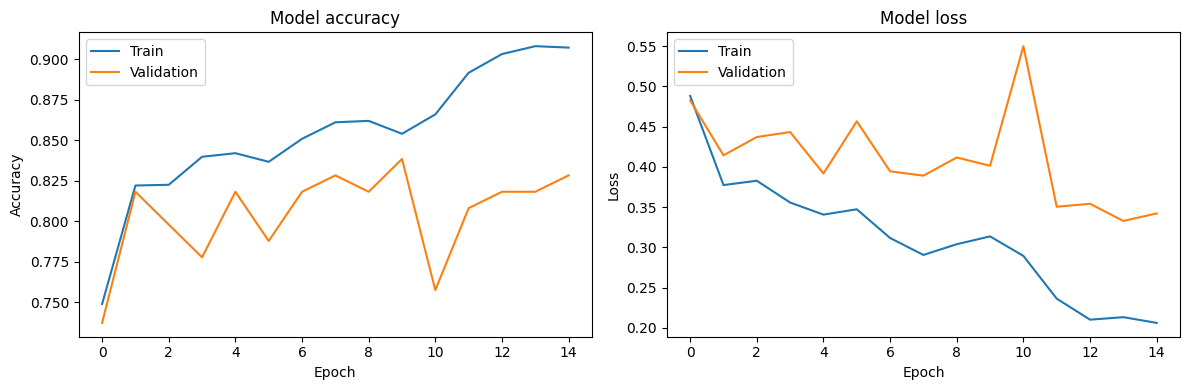

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.tight_layout()
plt.show()

## Model Evalutation

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
y_val = validation_generator.classes
y_pred = model.predict(validation_generator)
y_pred = np.argmax(y_pred,axis=1)

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 471ms/step


Classification Report:
              precision    recall  f1-score   support

      benign       0.86      0.81      0.84        54
   malignant       0.79      0.84      0.82        45

    accuracy                           0.83        99
   macro avg       0.83      0.83      0.83        99
weighted avg       0.83      0.83      0.83        99



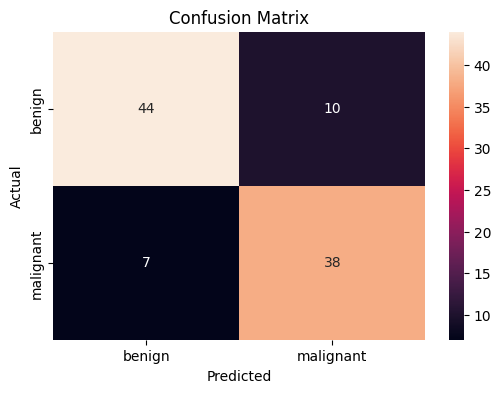

In [ ]:
# Metrics
print("Classification Report:")
print(classification_report(y_val, y_pred, target_names=validation_generator.class_indices.keys()))

# Confusion Matrix
conf_mat = confusion_matrix(y_val, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_mat, annot=True, fmt='d',
            xticklabels=validation_generator.class_indices.keys(),
            yticklabels=validation_generator.class_indices.keys())
plt.title("Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

In [ ]:
class_indices = validation_generator.class_indices
indices = {v:k for k,v in class_indices.items()}

In [ ]:
filenames = validation_generator.filenames

In [ ]:
val_df = pd.DataFrame()
val_df['filename'] = filenames
val_df['actual'] = y_val
val_df['predicted'] = y_pred
val_df['actual'] = val_df['actual'].apply(lambda x: indices[x])
val_df['predicted'] = val_df['predicted'].apply(lambda x: indices[x])
val_df.loc[val_df['actual']==val_df['predicted'],'Same'] = True
val_df.loc[val_df['actual']!=val_df['predicted'],'Same'] = False
val_df.head(10)

,filename,actual,predicted,Same
0,benign/1.jpg,benign,malignant,False
1,benign/10.jpg,benign,benign,True
2,benign/1003.jpg,benign,benign,True
3,benign/1006.jpg,benign,benign,True
4,benign/1013.jpg,benign,benign,True
5,benign/1018.jpg,benign,benign,True
6,benign/1019.jpg,benign,benign,True
7,benign/1023.jpg,benign,benign,True
8,benign/1025.jpg,benign,benign,True
9,benign/1029.jpg,benign,benign,True


In [ ]:
val_df = val_df.sample(frac=1).reset_index(drop=True)

## Grad-CAM

In [ ]:
#untuk mendefinisikan gambar
def readImage(path):
    img = load_img(path,color_mode='rgb',target_size=(img_size,img_size))
    img = img_to_array(img)
    img = img/255.

    return img


def display_images(temp_df):
    temp_df = temp_df.reset_index(drop=True)
    plt.figure(figsize=(20, 20))
    n = 0
    # Loop up to the smaller of 15 or the length of temp_df
    for i in range(min(15, len(temp_df))):
        n += 1
        plt.subplot(5, 5, n)
        plt.subplots_adjust(hspace=0.5, wspace=0.3)
        image = readImage(f"/content/drive/MyDrive/Skin Cancer/test/{temp_df.filename[i]}")
        plt.imshow(image)
        plt.title(f'A: {temp_df.actual[i]} P: {temp_df.predicted[i]}')

## Correctly Classified

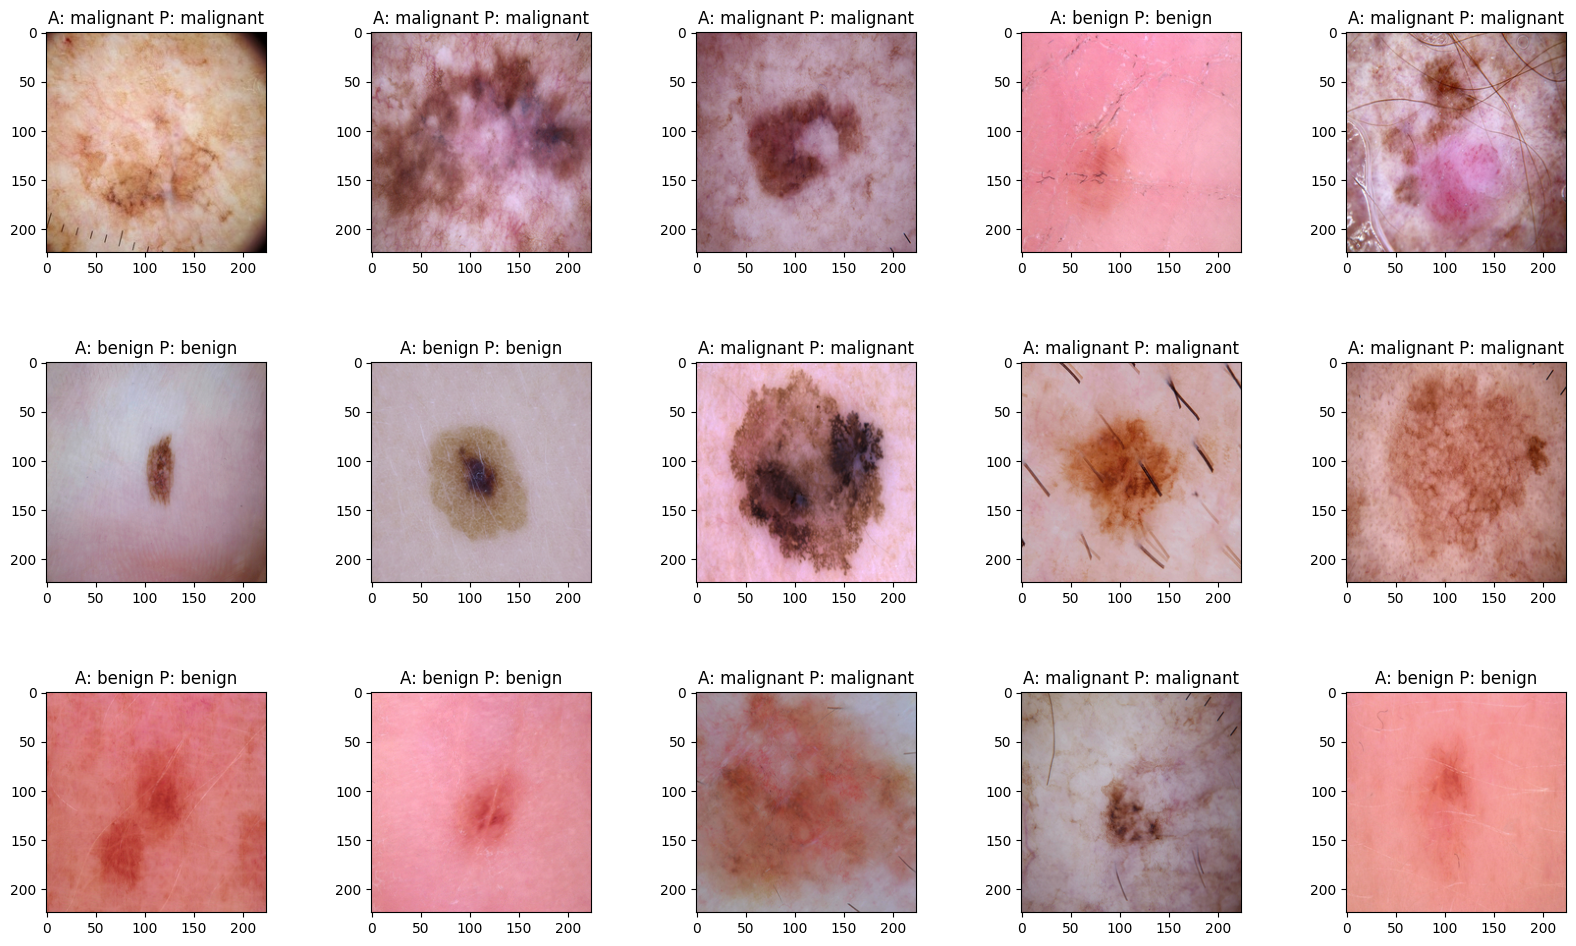

In [ ]:
display_images(val_df[val_df['Same']==True])

## Misclassified

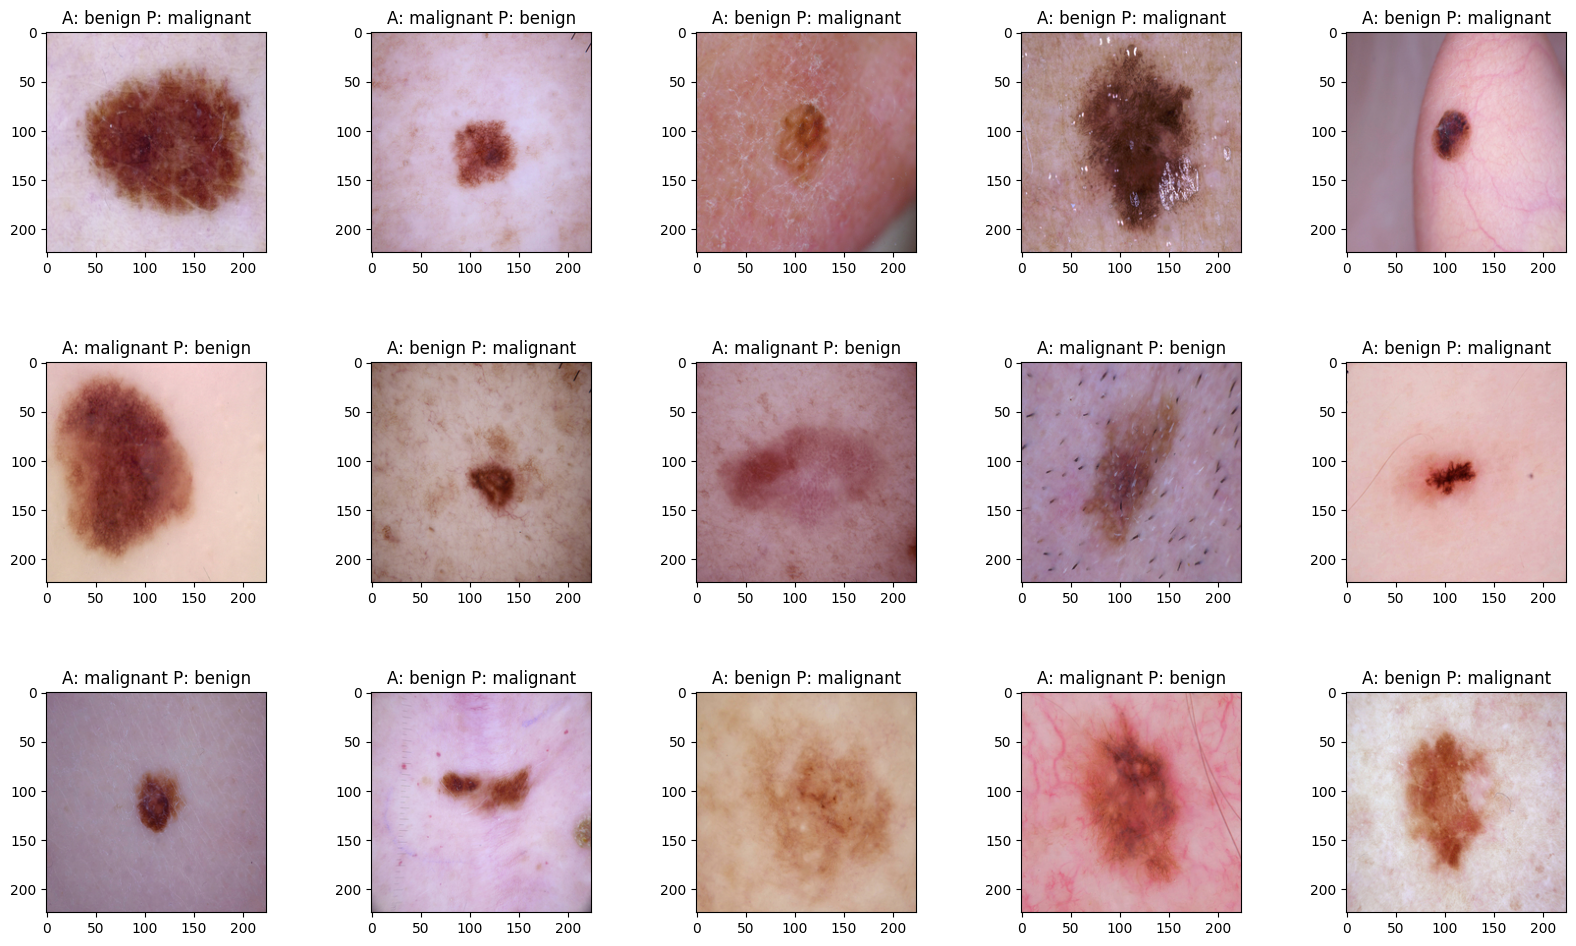

In [ ]:
display_images(val_df[val_df['Same']!=True])

Kanker kulit merupakan salah satu bentuk kanker yang paling umum dan mengancam jiwa yang terjadi diseluruh dunia. Kanker kulit memiliki dua jenis tipe yaitu ada yang ganas dan jinak.

Setelah melakukan beberapa kali percobaan dengan epoch yang berbeda-beda (10,13,15,20,25,30), saya menemukan bahwa dari hasil analisis ini pada epoch ke-20 memberikan hasil accuracy yang lebih baik dalam klasifikasi gambar dan best epoch menurut callback terdapat pada epoch ke-14.

Pada hasil Grad-CAM menunjukkan visualisasi heatmap untuk menjelaskan area mana pada gambar yang paling berkontribusi terhadap klasifikasi model prediksi.

Analisis model yang berhasil di prediksi:
*  Untuk malignant (ganas), area yang di highlight menunjukkan pola yang mencerminkan karakteristik kanker, seperti bertekstur atau ketidakteraturan.
*  Untuk benign (jinak), area yang di highlight menunjukkan pola yang relatif halus atau tidak menunjukkan tanda-tanda ganas.


